In [33]:
import pandas as pd
import numpy as np
from typing import Optional
from pathlib import Path
import logging
import plotly.express as px
import itertools

logger = logging.getLogger(__name__)

In [34]:
# sample config
data_config = { 
    "minimal": True,
    "folder": "/Users/henrykraessig/code/bdb2025/data/", 
    "targetfolder": "./data", 
    "mask": 0.15, 
    "train": 0.7, 
    "val": 0.15, 
    "test": 0.15, 
    "interp": 40,
    "premask": True
}

In [35]:
# load parts of the data
# take in paths, return a couple dataframes
def load_csv_data(
    paths: list[Path]
) -> list[pd.DataFrame]:
    # TODO: look into reading from template, i.e. tracking_week_*.csv
    return [pd.read_csv(path) for path in paths]


def load_tracking_data(
    weeks: Optional[int | list[int]]=None,
    folder: Optional[Path]=None,
) -> pd.DataFrame:
   
    MIN_WEEK = 1
    MAX_WEEK = 9

    if not weeks:
        # defualt to all data
        weeks = range(MIN_WEEK, MAX_WEEK + 1)
    
    if isinstance(weeks, int):
        weeks = [weeks]
    weeks = set(weeks)
    
    for week in weeks:
        assert isinstance(week, int) and week >= MIN_WEEK and week <= MAX_WEEK, \
        f"provide integer weeks between {MIN_WEEK} and {MAX_WEEK}"

    print(f"reading data from weeks: {weeks}")

    # load data from a folderectory
    if folder and folder.exists():
        logger.info(f"reading tracking from {folder}")
        paths = [Path(folder, f'tracking_week_{n}.csv') for n in weeks]

        dfs = load_csv_data(paths)
        return pd.concat(dfs)
    
    raise FileNotFoundError


def load_player_data(
    folder: Optional[Path]=None,
) -> pd.DataFrame:

    if folder and folder.exists():
        logger.info(f"reading player data from {folder}")
        path = Path(folder, 'players.csv')

        return pd.read_csv(path)
    

def load_play_data(
        folder: Optional[Path]=None,
) -> pd.DataFrame:
    

    if folder and folder.exists():
        logger.info(f"reading play data from {folder}")
        path = Path(folder, 'plays.csv')

    return pd.read_csv(path)


def load_player_play_data(
        folder: Optional[Path]=None,
) -> pd.DataFrame:
    

    if folder and folder.exists():
        logger.info(f"reading play data from {folder}")
        path = Path(folder, 'player_play.csv')

    return pd.read_csv(path)

In [36]:
# simple graphing utility for troubleshooting
def debug_plot(tracking_df: pd.DataFrame):
    # collect one play
    gameid = tracking_df['gameId'].iat[0]
    playid = tracking_df['playId'].iat[0]

    df = tracking_df.loc[(tracking_df['gameId'] == gameid) & (tracking_df['playId'] == playid)]

    fig = px.scatter(
        df,
        x="x",
        y="y",
        animation_frame="frameId",
        title=f"test"
    )


    return fig

In [37]:
if data_config['minimal']: 
    tracking = load_csv_data([Path("minimal_tracking.csv")])[0]

players = load_player_data(Path(data_config['folder']))
plays = load_play_data(Path(data_config["folder"]))
player_plays = load_player_play_data(Path(data_config["folder"]))

In [38]:
# perform easy filters on the data

def filter_pass_plays(): 
    ...
    

In [39]:
# clean the data

def clean_tracking_angles(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    logger.info("cleaning tracking data angles")
    # angles to radians
    tracking_df['o'] = ((-1 * tracking_df['o'] + 90) % 360) * np.pi / 180
    tracking_df['dir'] = ((-1 * tracking_df['dir'] + 90) % 360) * np.pi / 180

    return tracking_df


def standardize_tracking_plays(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    logger.info("standardizing tracking data")
    # standardize locations to the ball snap location
    ball = (
        tracking_df
        .loc[
            (tracking_df['event'] == 'ball_snap') & 
            (tracking_df['club'] == 'football'),
            
            ['gameId', 'playId', 'frameId', 'x', 'y']
        ]
    )
    tracking_df = tracking_df.merge(
        ball, # ball info for starting time
        how='left', 
        on=('gameId', 'playId'),
        suffixes=('', '_ball_snap')
    )

    tracking_df['x'] = tracking_df['x'] - tracking_df['x_ball_snap']
    tracking_df['y'] = tracking_df['y'] - tracking_df['y_ball_snap']

    # normalize play directions to the right
    tracking_df['x'] = ((tracking_df['playDirection'] == 'left') * -2 + 1) * tracking_df['x']
    tracking_df['o'] = ( ((tracking_df['playDirection'] == 'left') * np.pi) + tracking_df['o'] ) % (2 * np.pi) 
    tracking_df['dir'] = ( ((tracking_df['playDirection'] == 'left') * np.pi) + tracking_df['dir'] ) % (2 * np.pi) 

    # x and y components of orientation and velocity
    tracking_df['ox'] = np.cos(tracking_df['o'])
    tracking_df['oy'] = np.sin(tracking_df['o'])

    tracking_df['vx'] = np.cos(tracking_df['dir']) * tracking_df['s']
    tracking_df['vy'] = np.sin(tracking_df['dir']) * tracking_df['s']

    return tracking_df


def clean_player_data(player_df: pd.DataFrame) -> pd.DataFrame:
    logger.info("cleaning player data")
    
    # clean height
    feet = pd.to_numeric(player_df['height'].str.split('-', expand=True)[0])
    inches = pd.to_numeric(player_df['height'].str.split('-', expand=True)[1])
    player_df['height_inches'] = 12 * feet + inches

    # create zscore for height
    player_df['height_z'] = (player_df['height_inches'] - player_df['height_inches'].mean()) / player_df['height_inches'].std()
    player_df['weight_z'] = (player_df['weight'] - player_df['weight'].mean()) / player_df['weight'].std()

    return player_df


In [40]:
tracking = clean_tracking_angles(tracking)
tracking = standardize_tracking_plays(tracking)


players = clean_player_data(players)


In [41]:
def filter_play_start_frames(tracking_df: pd.DataFrame) -> pd.DataFrame:
    # standardize frameId to 0 at snap & remove presnap frames
    tracking_df['frameId'] = tracking_df['frameId'] - tracking_df['frameId_ball_snap']
    return tracking_df.loc[tracking_df['frameId'] >=  0]


def filter_play_end_frames(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    # create a stop point variable to track frames after the play
    tracking_df['stop_point'] = pd.NA
    tracking_df.loc[tracking_df['event'].isin(['pass_outcome_incomplete', 'qb_sack', 'tackle']), 'stop_point'] = True 
    # fill stopping points forward to filter out moments after a defined route stop
    tracking_df['stop_point'] = tracking_df.groupby(['gameId', 'playId', 'nflId'])['stop_point'].ffill()

    return tracking_df.loc[tracking_df['stop_point'].isna()].drop(columns='stop_point') # remove redundant column


def filter_route_end_frames(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    # potentially complex logic to find when a route runner's designed route has ended
    ...


def filter_football_tracking_frames(tracking_df: pd.DataFrame) -> pd.DataFrame: 
    return tracking_df.loc[tracking_df['club'] != 'football']


In [42]:
tracking = filter_play_start_frames(tracking)
tracking = filter_play_end_frames(tracking)
# tracking = filter_football_tracking_frames(tracking)

In [53]:
routes_per_play = tracking.groupby(['gameId', 'playId'])['nflId'].nunique(dropna=False).iloc[0]
assert (tracking.groupby(['gameId', 'playId'])['nflId'].nunique(dropna=False) == routes_per_play).all()

routes_per_play

np.int64(23)

In [51]:
# perform unique data transforms
def find_play_invariant_columns(play_df: pd.DataFrame, tracking_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]: 
    # grab the column names for columns in the tracking data that won't change over the course of a given play
    cols_static = (tracking_df.groupby(['gameId', 'playId']).nunique() == 1).all(axis=0) # series w/ index colname and boolean value
    invariant_columns = cols_static.index[cols_static].tolist()

    tracking_invariant = tracking_df.groupby(['gameId', 'playId'])[invariant_columns].first()

    # tack them on to the plays dataframe
    play_df = play_df.merge(
        tracking_invariant,
        how='left', 
        on=('gameId', 'playId'),
    )    

    # remove them from the tracking dataframe
    return play_df, tracking_df.drop(columns=invariant_columns)


def find_player_play_invariant_columns(player_play_df: pd.DataFrame, tracking_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]: 
    # grab the column names for columns in the tracking data that won't change over the course of a given play for a given player
    cols_static = (tracking_df.groupby(['gameId', 'playId', 'nflId']).nunique() == 1).all(axis=0) # series w/ index colname and boolean value
    invariant_columns = cols_static.index[cols_static].tolist()

    tracking_invariant = tracking_df.groupby(['gameId', 'playId', 'nflId'])[invariant_columns].first()


    # tack them on to the plays dataframe
    player_play_df = player_play_df.merge(
        tracking_invariant,
        how='left', 
        on=('gameId', 'playId', 'nflId'),
    )    

    # remove them from the tracking dataframe
    return player_play_df, tracking_df.drop(columns=invariant_columns)


def clean_player_play_data(player_play_df: pd.DataFrame, play_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]: 

    player_play_df['is_ball'] = (player_play_df['club'] == 'football')

    merged = player_play_df[['gameId', 'playId', 'club']].copy().merge(play_df[['gameId', 'playId', 'possessionTeam', 'defensiveTeam']].copy(), how='left', on=('gameId', 'playId'))

    player_play_df['offense'] = (merged['club'] == merged['possessionTeam'])
    player_play_df['defense'] = (merged['club'] == merged['defensiveTeam'])

    return player_play_df, play_df


def interpolate_tracking_frames(tracking_df: pd.DataFrame, interp_frames: int=40) -> pd.DataFrame: 
    from scipy.interpolate import CubicSpline

    play_index = tracking_df.set_index(['gameId', 'playId']).sort_index()

    num_obs = interp_frames
    interpolated_columns = ['x', 'y', 'ox', 'oy', 'vx', 'vy', 'a']
    ids = play_index.index.unique()
    num_plays = len(ids)
    routes_per_play = tracking_df.groupby(['gameId', 'playId'])['nflId'].nunique(dropna=True).max()
    id_cols = ['gameId', 'playId', 'nflId', 'frameId']

    print(f"interpolating {len(interpolated_columns)} columns of data")
    print(f"columns: {interpolated_columns}")
    # array for interpolated movement
    movement_arr = np.zeros( (num_plays, routes_per_play, num_obs, len(interpolated_columns)), dtype=np.float32)
    nfl_ids = np.empty( (num_plays, routes_per_play), dtype=np.float32 )

    for i, (gameid, playid) in enumerate(ids): 
        
        play: pd.DataFrame = play_index.loc[gameid, playid]
        
        for ii, nflid in enumerate(play['nflId'].dropna().unique()):

            player: pd.DataFrame = play.loc[play['nflId'] == nflid]
            min_frame = player['frameId'].min()
            frame_range = player['frameId'].max() - min_frame
            t = np.array((player['frameId'] - min_frame) / frame_range)

            player_data = np.array(player[interpolated_columns])

            # smooth the info about the player over time
            spline = CubicSpline(t, player_data, axis=0, extrapolate=False)

            # take n observations
            observation_times = np.arange(num_obs) / num_obs

            # populate an array with smoothed values
            movement_arr[i, ii, ...] = spline(observation_times)
            nfl_ids[i, ii] = nflid



    # create new tracking dataframe
    tracking_df_data = movement_arr.reshape((-1, len(interpolated_columns)))
    id_arr = np.stack([
        np.repeat(ids.get_level_values(0), num_obs * routes_per_play),
        np.repeat(ids.get_level_values(1), num_obs * routes_per_play),
        nfl_ids.flatten().repeat(num_obs),
        np.tile(np.arange(num_obs), routes_per_play * num_plays)
    ], axis=-1)


    tracking_df = pd.DataFrame(
        data = np.concat([id_arr, tracking_df_data], axis=-1), 
        columns=id_cols + interpolated_columns
    )

    return tracking_df



def player_relative_positions(tracking_df: pd.DataFrame, player_play_df: pd.DataFrame):
    """For each player/play, make the player's position relative to their previous frame,
    and add start postions for each player/play
    """
    
    starts = (
        tracking_df
        .groupby(['gameId', 'playId', 'nflId'])
        [['x', 'y']]
        .first()
        .rename(columns={'x': 'x_start', 'y': 'y_start'})
    )


    tracking_df[['x', 'y']] = tracking_df.groupby(['gameId', 'playId', 'nflId'])[['x', 'y']].transform(lambda x: x - x.iloc[0])



    # join starts with player_play_df
    player_play_df = player_play_df.merge(
        starts, 
        how='left', 
        on=('gameId', 'playId', 'nflId')
    )

    return tracking, player_play_df



In [52]:
plays, tracking = find_play_invariant_columns(plays, tracking)
player_plays, tracking = find_player_play_invariant_columns(player_plays, tracking)
player_plays, plays = clean_player_play_data(player_plays, plays)
tracking, player_plays = player_relative_positions(tracking, player_plays)

In [54]:
# tracking = interpolate_tracking_frames(tracking)

In [55]:
# mirror tracking data
# TODO: fix mirror starts when relative positions are used
def mirror_tracking_data(tracking_df: pd.DataFrame) -> pd.DataFrame:
    logger.info("mirroring tracking data")
    mirrored_df = tracking_df.copy()

    mirrored_df['y'] = mirrored_df['y'] * -1
    mirrored_df['vy'] = mirrored_df['vy'] * -1
    mirrored_df['oy'] = mirrored_df['oy'] * -1

    mirrored_df['mirrored'] = True
    tracking_df['mirrored'] = False

    return pd.concat([tracking_df, mirrored_df])


In [56]:
tracking = mirror_tracking_data(tracking)

<Axes: >

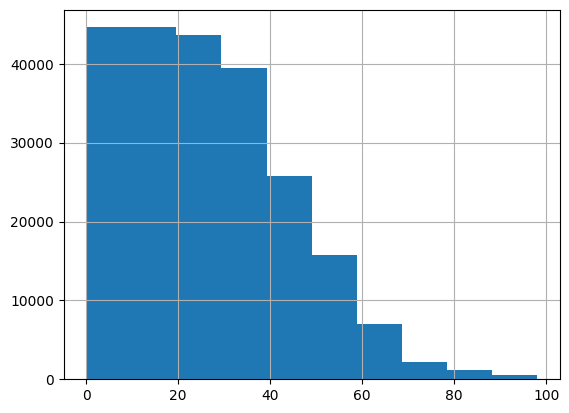

In [57]:
tracking['frameId'].hist()

In [105]:
# create a dataset for a certian model/task
from torch.utils.data import Dataset, DataLoader
import torch

class NflDataset(Dataset): 
    """Default dataset"""

    def __init__(
        self, 
        tracking_df: pd.DataFrame, 
        player_play_df: pd.DataFrame,
        play_df: pd.DataFrame, 
        player_df: pd.DataFrame, 
    ):
        
        # base dataframe for getting inputs.
        # for each sample, get a B, P, F tensor

        # these are the base columns to be used as an input
        # the point is for these columns to be as general as possible, 
        # to be applied to any potential sports tracking dataset

        # think about solving the player ordering problem!

        id_cols = ['gameId', 'playId', 'mirrored', 'nflId']

        tracking_cols = [
            'gameId', 'playId', 'nflId', 'mirrored', 'frameId', 'x', 'y', 'vx', 'vy', 'o', 'dir', 'a'
        ]

        player_play_cols = [
            'gameId', 'playId', 'nflId', 'is_ball', 'offense', 'defense', 'x_start', 'y_start'
        ]

        play_cols = [
            'gameId', 'playId', 'x_ball_snap', 'y_ball_snap'
        ]

        player_cols = [
            'nflId', 'height_z', 'weight_z', 'position'
        ]

        tracking_df = tracking_df[tracking_cols].copy()


        play_lens = tracking_df.groupby(['gameId', 'playId'])['frameId'].max()
        max_frameid = int(play_lens.mean() + 2 * play_lens.std())
        
        new_index = itertools.product(tracking_df.set_index(['gameId', 'playId', 'nflId', 'mirrored']).index.unique().tolist(), range(max_frameid))
        new_index = [(*p, f) for p, f in new_index]

        new_index = pd.MultiIndex.from_tuples(new_index, names=['gameId', 'playId', 'nflId', 'mirrored', 'frameId'])

        tracking_df = tracking_df.set_index(['gameId', 'playId', 'nflId', 'mirrored', 'frameId']).reindex(new_index).fillna(0)
        tracking_df = tracking_df.reset_index()
        tracking_df['nflId'] = tracking_df['nflId'].fillna(-1)
        tracking_df = tracking_df.set_index(['gameId', 'playId', 'nflId', 'mirrored'])
        wide_tracking_df = tracking_df.pivot_table(index=tracking_df.index.names, columns='frameId').pipe(
            lambda d: d.set_axis([f'{col}_{id_}' for col, id_ in d.columns], axis=1)
        ).reset_index()

        merged_df = pd.get_dummies(
            wide_tracking_df
            .merge(player_play_df[player_play_cols], how='left', on=('gameId', 'playId', 'nflId'))
            .merge(play_df[play_cols], how='left', on=('gameId', 'playId'))
            .merge(player_df[player_cols], how='left', on=('nflId'))
        )

        merged_df = merged_df.set_index(['gameId', 'playId', 'mirrored']).sort_index()
        play_index = merged_df.index.unique()

        data_cols = list(set(merged_df.columns).difference(id_cols))
        num_data_cols = len(data_cols)
        num_plays = len(play_index)
        routes_per_play = merged_df.groupby(['gameId', 'playId', 'mirrored'])['nflId'].nunique(dropna=False).iloc[0]
        assert (merged_df.groupby(['gameId', 'playId', 'mirrored'])['nflId'].nunique(dropna=False) == routes_per_play).all(), \
        "Different values across player dimension"
        
        self.data = np.zeros((num_plays, routes_per_play, num_data_cols), dtype=np.float32)

        for i, (gameid, playid, mirrored) in enumerate(play_index): 

            data = merged_df.loc[(gameid, playid, mirrored), data_cols].to_numpy(dtype=np.float32)
            self.data[i, ...] = data

        self.torch_data = torch.Tensor(self.data)
        return
    
    

    def __len__(self): 
        return self.data.shape[0]


    def __getitem__(self, idx: int): 
        return self.torch_data[idx]



class MaskedNflDataset(NflDataset): 

    def __init__(
        self, 
        tracking_df: pd.DataFrame,
        player_play_df: pd.DataFrame,
        play_df: pd.DataFrame, 
        player_df: pd.DataFrame, 
    ):
        super().__init__(tracking_df, player_play_df, play_df, player_df)        



        return 

    
        
        

In [106]:
NflDataset(tracking, player_plays, plays, players)[0].shape

torch.Size([23, 583])